# Reporting

This notebook computes usage per instruments, users and divisions. 


**Before running this notebook:** 
1. Update the folder
2. Update the start date 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from usagestats.bookingdb import BookingDB
from usagestats import visual
from datetime import datetime, timedelta
import pytz
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

local_tz = pytz.timezone("Europe/London")

# UPDATE THE FOLDER HERE
folder = Path('/run/user/1000/gvfs/smb-share:server=istore,share=microscopy_group_share,user=jeromeb/Admin/Usage Stats/2025')
# UPDATE THE DATE HERE
start_date = datetime.fromisoformat('2024-11-04').replace(tzinfo=local_tz)
num_weeks = 52
end_date = start_date + timedelta(weeks=num_weeks)  # iso-format data yyyy-mm-dd

db_file = folder / "bookings.db"
drop_bookings_type = ["service", "maintenance", "training"]
drop_instrument = ["Analysis PC1", "Analysis PC2", "Analysis PC3", "Analysis PC4"]

with BookingDB(db_file) as db:
    bookings = db.get_events_in_range(start_date, end_date)


# fix booking types
def get_type_from_str(x):
    types = {
        "serv": "service",
        "maint": "maintenance",
        "train": "training",
        "maintenace": "maintenance",
    }
    for y in types:
        if x.lower().find(y) >= 0:
            return types[y]
    return "default"


bookings["type"] = [get_type_from_str(x) for x in bookings["subject"]]

In [5]:
newusers = bookings[bookings['group']=='Unknown'][['user','group','division']].drop_duplicates().reset_index()

In [11]:
all_users = bookings[['email','user','group','division']].drop_duplicates().reset_index(drop=True)
all_users['email'] = all_users['email'].apply(lambda x:x.split("@")[0])
all_users.to_csv('/run/user/1000/gvfs/smb-share:server=istore,share=microscopy_group_share,user=jeromeb/Admin/Usage Stats/2026/users.csv')
all_users

,email,user,group,division
0,mbassal,Mahmoud Bassal,McMahon,Neurobiology
1,jycwong,Janice Wong,Ramakrishnan L,University
2,ajansson,Anna Jansson,Schafer,Neurobiology
3,bingnanl,Bingnan Lyu,Ramakrishnan L,University
4,rhdina,Dina Ratsimandresy,Light Microscopy,Cell Biology
...,...,...,...,...
188,ejonesevans,Esther Jones Evans,Levin-Konigsberg,Cell Biology
189,rjudy,Ryan Judy,Hedge,Cell Biology
190,hpizarro,Héctor Pizarro,Unknown,Unknown
191,vhale,Victoria Hale,Allegretti,Structural Studies


## Booking by type

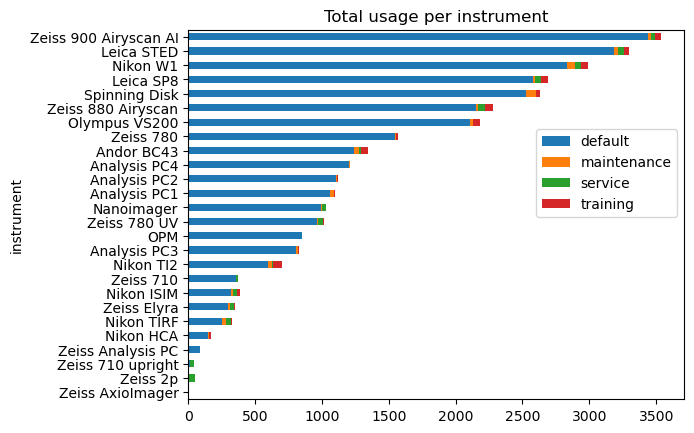

In [3]:
hours_insts = (
    bookings.groupby(["type", "instrument"], as_index=False)
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .pivot(index="instrument", values="hours", columns="type")
    .fillna(0)
    .sort_values("default")
)
hours_insts.to_csv(folder / "booking-by-type-and-instrument.csv")

hours_insts.plot(kind="barh", stacked=True)
plt.legend(bbox_to_anchor=(1, 0.75))
plt.title("Total usage per instrument")
plt.savefig(
    folder / "usage-per-type-per-instrument.pdf", pad_inches=1.2, bbox_inches="tight"
)

## Drop maintenance and analysis pc

In [4]:
# excludes special bookings
bookings = bookings[~bookings["type"].isin(drop_bookings_type)]
# excludes instruments
bookings = bookings[~bookings["instrument"].isin(drop_instrument)]
# exclude unknownbookings = bookings[bookings["group"] != "Unknown"]
bookings = bookings[bookings["division"] != "Unknown"]
bookings.head()

,hours,start,end,user,group,division,instrument,type,subject
1388,3.0,2025-07-01 19:31:00+00:00,2025-07-01 22:31:00+00:00,Andrew Oliphant,Hastings,Neurobiology,Andor BC43,default,drew
1389,3.0,2025-03-18 13:01:00+00:00,2025-03-18 16:01:00+00:00,Sonia Agüera Gonzalez,McDole,Cell Biology,Andor BC43,default,sonia aguera
1390,2.0,2025-06-12 13:31:00+00:00,2025-06-12 15:31:00+00:00,Chisato Tsuji,Carter,Structural Studies,Andor BC43,default,chisato andor
1391,3.0,2025-01-22 15:01:00+00:00,2025-01-22 18:01:00+00:00,Oliver Knowles,Allegretti,Structural Studies,Andor BC43,default,oliver
1392,1.0,2025-07-09 16:01:00+00:00,2025-07-09 17:01:00+00:00,Tomás Pais de Azevedo,Light Microscopy,Cell Biology,Andor BC43,default,tomas and felix


In [5]:
info_str = visual.get_title_str(bookings, start_date, end_date)

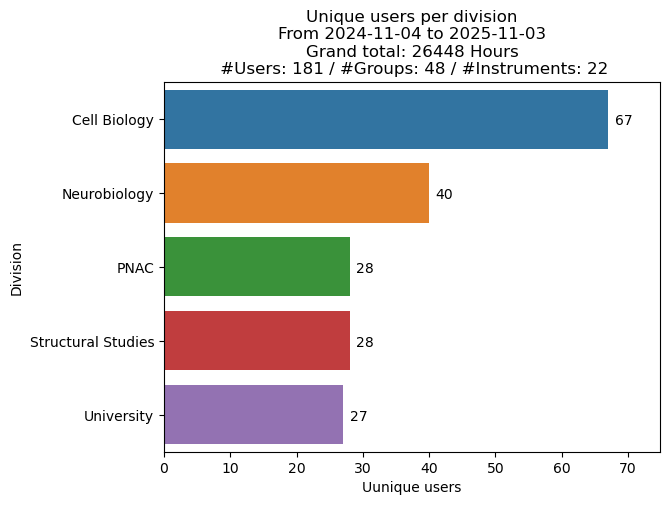

In [6]:
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)
unique_users = unique_users[unique_users["division"] != "Unknown"]
user_div = (
    unique_users.groupby("division")[["name"]]
    .count()
    .sort_values("name", ascending=False)
)
ax = sns.barplot(data=user_div, x="name", y="division", hue="division")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Uunique users")
plt.ylabel("Division")
plt.title("Unique users per division" + info_str)
plt.savefig(folder / "users-per-division.pdf", pad_inches=1.2, bbox_inches="tight")

## Usage per division

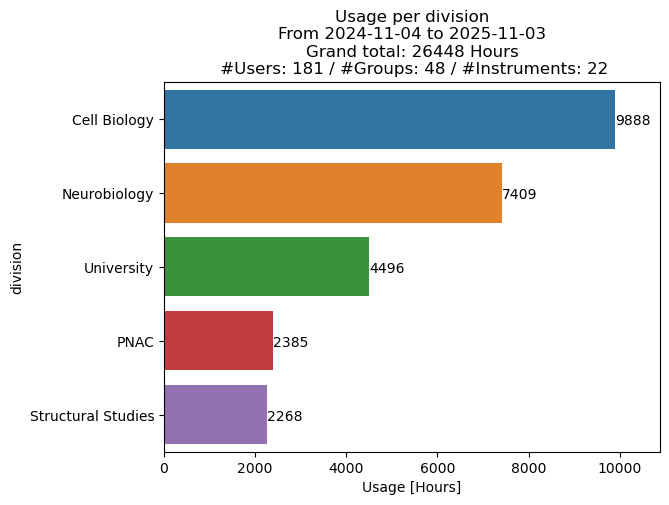

In [7]:
hours_div = (
    bookings.groupby("division")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .sort_values("hours", ascending=False)
)

ax = sns.barplot(data=hours_div, x="hours", y="division", hue="division")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Usage [Hours]")
plt.title("Usage per division" + info_str)
plt.savefig(folder / "hours-per-division.pdf", pad_inches=1.2, bbox_inches="tight")

## Usage per group

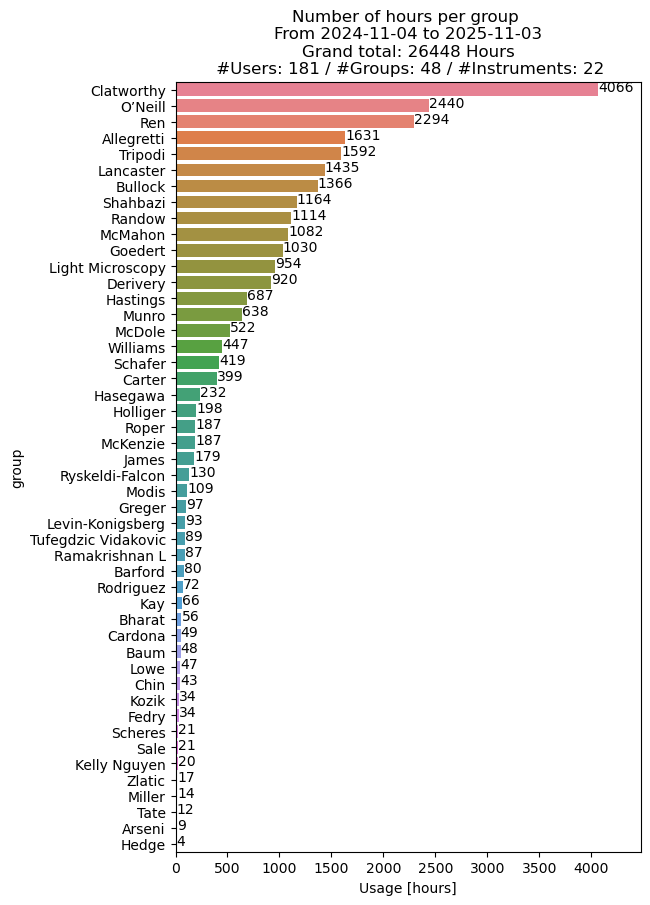

In [8]:
from usagestats import visual

hours_grps = (
    bookings.groupby("group")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .sort_values("hours", ascending=False)
)

f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=hours_grps, x="hours", y="group", hue="group")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Usage [hours]")
plt.title("Number of hours per group " + info_str)
plt.savefig(folder / "hours-per-group.pdf", pad_inches=1.2, bbox_inches="tight")

## Usage by instrument

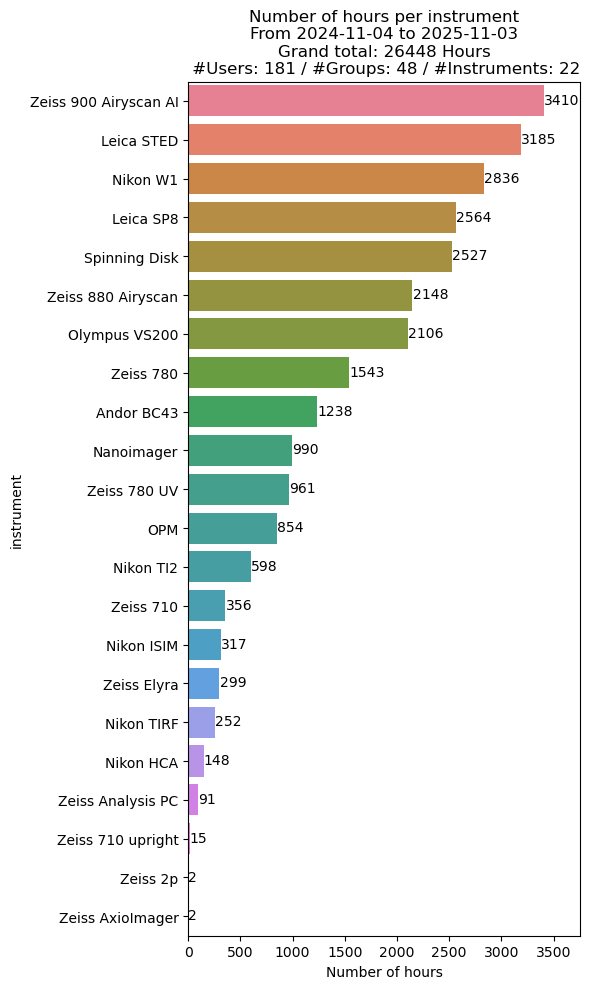

In [9]:
from usagestats import visual

hours_insts2 = (
    bookings.groupby("instrument")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .fillna(0)
    .sort_values("hours", ascending=False)
)
f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=hours_insts2, x="hours", y="instrument", hue="instrument")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Number of hours")
plt.title("Number of hours per instrument" + info_str)
plt.tight_layout()
plt.savefig(folder / "hours-per-instruments.pdf", pad_inches=1.2, bbox_inches="tight")

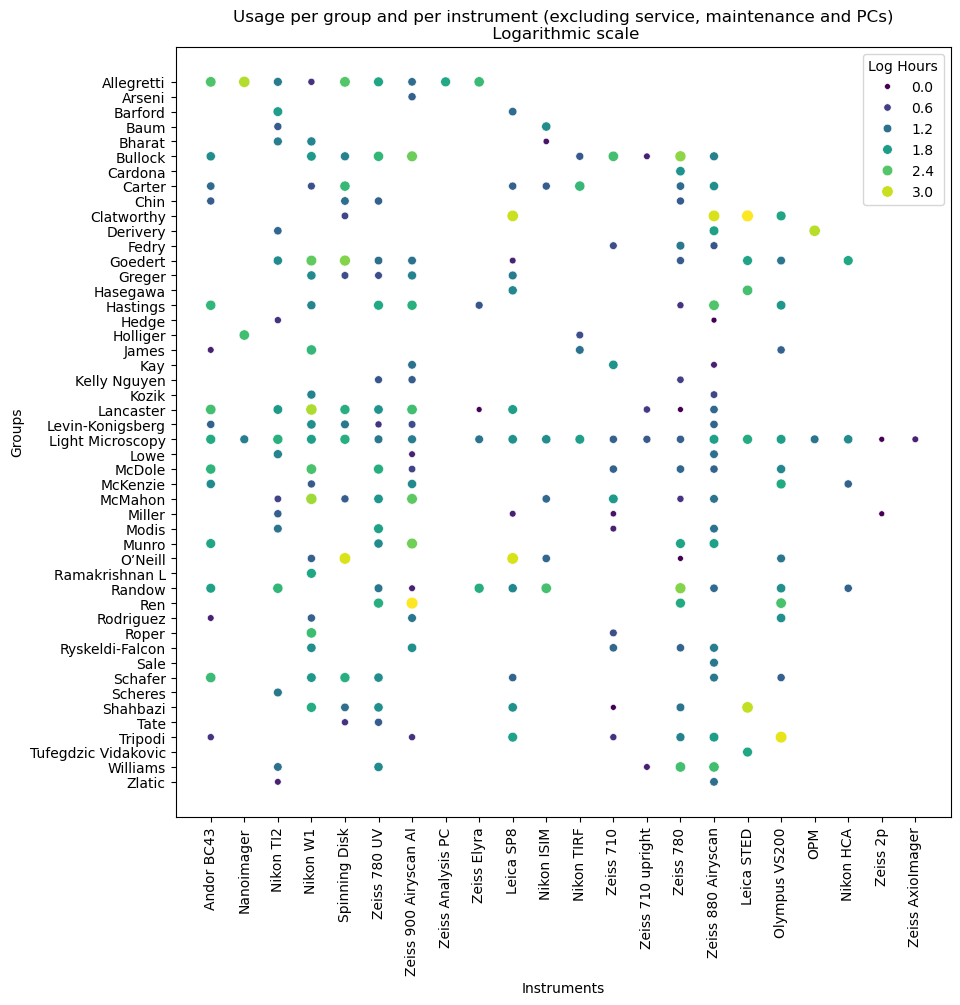

In [10]:
import math

# bookings.groupby(['Group','Instrument'], as_index=False)['Hours'].agg('sum').pivot(index="Group",columns="Instrument",values='Hours').fillna(0).to_csv('usage-per-group-per-instrument.csv')
f, x = plt.subplots(figsize=(10, 10))
tmp = bookings.groupby(["group", "instrument"], as_index=False)["hours"].agg("sum")
tmp["hours"] = [math.log10(x) for x in tmp["hours"]]
cmap = sns.color_palette("viridis", as_cmap=True)
# order = tmp.groupby('Group').agg(time=('Hours',sum)).sort_values('time',ascending=False).index.values
sns.scatterplot(
    data=tmp, x="instrument", y="group", size="hours", hue="hours", palette=cmap
)
plt.xticks(rotation=90)
plt.ylabel("Groups")
plt.xlabel("Instruments")
plt.title(
    "Usage per group and per instrument (excluding service, maintenance and PCs)\n Logarithmic scale"
)
plt.legend(title="Log Hours")
plt.savefig(
    folder / "usage-per-group-per-instrument.pdf", pad_inches=1.2, bbox_inches="tight"
)

Number of unique user per instrument

In [23]:
def unique_user(x):
    return len(x.unique())

unique_user_per_insts= bookings.groupby("instrument").agg(
    unique_user=pd.NamedAgg(column="user", aggfunc=unique_user),
    hours=pd.NamedAgg(column="hours", aggfunc="sum"),
    divisions = pd.NamedAgg(column="division", aggfunc=unique_user),
)

unique_user_per_insts.sort_values('unique_user',inplace=True,ascending=False)
unique_user_per_insts.to_csv(folder/'unique_users_per_systems.csv')
unique_user_per_insts

,unique_user,hours,divisions
instrument,,,
Zeiss 880 Airyscan,43,2148.000000,5
Nikon W1,41,2836.500000,5
Zeiss 780,40,1543.166667,4
Zeiss 900 Airyscan AI,39,3410.250000,4
Leica SP8,38,2564.166667,5
Zeiss 780 UV,36,961.500000,5
Nikon TI2,33,598.166667,5
Spinning Disk,32,2527.483333,5
Olympus VS200,32,2106.250000,4


In [24]:
unique_group_per_insts = bookings.groupby("instrument")['group'].nunique().sort_values()
unique_group_per_insts.to_csv(folder/'unique_group_per_systems.csv')
unique_group_per_insts

instrument
Zeiss AxioImager          1
Zeiss Analysis PC         1
Zeiss 2p                  2
OPM                       2
Nanoimager                3
Nikon HCA                 4
Zeiss 710 upright         4
Nikon TIRF                5
Zeiss Elyra               5
Leica STED                6
Nikon ISIM                7
Zeiss 710                12
Olympus VS200            13
Leica SP8                14
Spinning Disk            15
Andor BC43               16
Nikon TI2                17
Zeiss 780                20
Zeiss 780 UV             20
Zeiss 900 Airyscan AI    21
Nikon W1                 22
Zeiss 880 Airyscan       24
Name: group, dtype: int64

Select a subgroup of systems

In [13]:
subgroup = ["Zeiss 780 UV", "Zeiss 780", "Zeiss 2p", "Zeiss 710 upright", "Zeiss 710"]
filtered = bookings[bookings["instrument"].isin(subgroup)]
print(f'subgroup: {subgroup}\n unique users: {len(filtered["user"].unique())}\n groups: {len(filtered["group"].unique())}')


subgroup: ['Zeiss 780 UV', 'Zeiss 780', 'Zeiss 2p', 'Zeiss 710 upright', 'Zeiss 710']
 unique users: 59
 groups: 29


<Axes: xlabel='unique_user', ylabel='hours'>

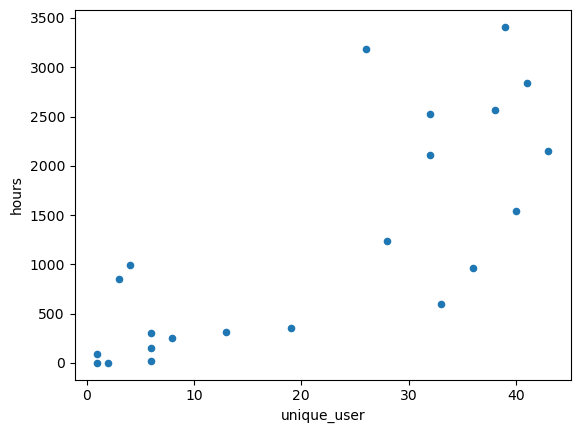

In [14]:
unique_user_per_insts.plot(kind='scatter', x='unique_user',y='hours')

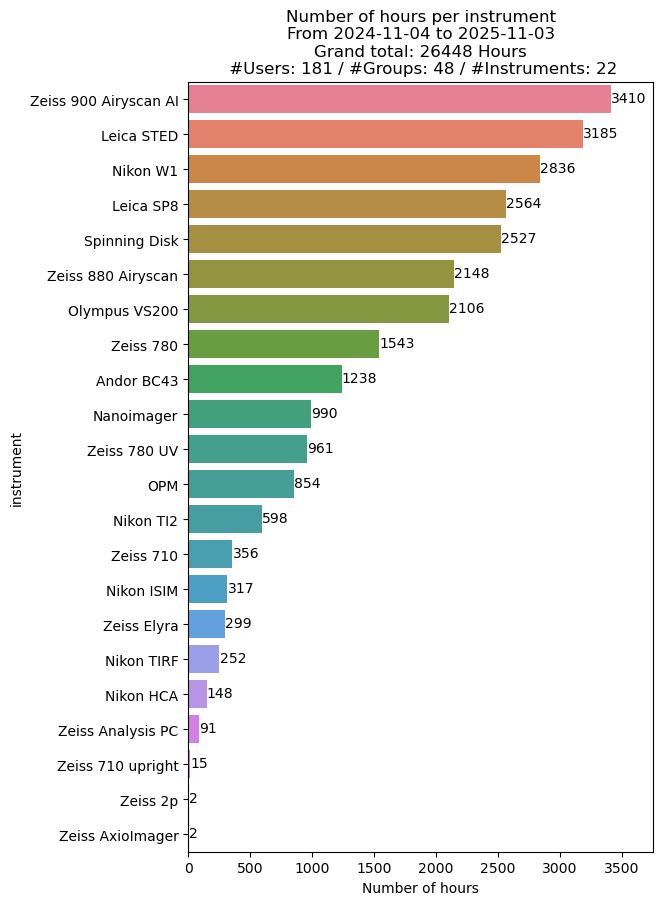

In [15]:
user_insts = (
    bookings.groupby("instrument")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .fillna(0)
    .sort_values("hours", ascending=False)
)

f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=user_insts, x="hours", y="instrument", hue="instrument")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Number of hours")
plt.title("Number of hours per instrument" + info_str)
plt.savefig(folder / "hours-per-instruments.pdf", pad_inches=1.2, bbox_inches="tight")

## By user

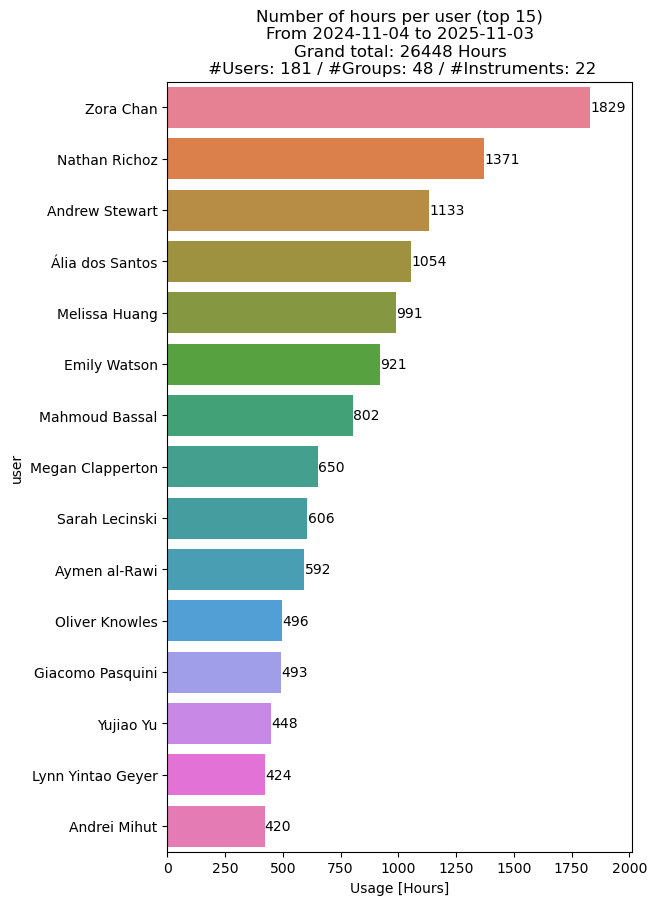

In [25]:
from usagestats import visual

top_users = (
    bookings.groupby("user")
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .sort_values("hours", ascending=False)
)

f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=top_users.iloc[:15], x="hours", y="user", hue="user")
visual.show_values_on_bars(ax, "h", hspace=0.4)
plt.xlabel("Usage [Hours]")

plt.title("Number of hours per user (top 15)" + info_str)
plt.savefig(folder / "hours-per-userspdf", pad_inches=1.2, bbox_inches="tight")

In [26]:

total_hours_per_user = bookings.groupby(['instrument','user'])['hours'].sum().reset_index()

idx = total_hours_per_user.groupby('instrument')['hours'].idxmax()

top_user_per_instrument = total_hours_per_user.loc[idx].reset_index(drop=True)

print("Top user per instrument:")
top_user_per_instrument

Top user per instrument:


,instrument,user,hours
0,Andor BC43,Oliver Knowles,120.0
1,Leica SP8,Nathan Richoz,641.5
2,Leica STED,Nathan Richoz,680.5
3,Nanoimager,Ália dos Santos,774.5
4,Nikon HCA,Melissa Huang,89.5
5,Nikon ISIM,Prathyush Pothukuchi,119.5
6,Nikon TI2,Chi Jie Matthew Yip,145.0
7,Nikon TIRF,Richard Wademan,64.0
8,Nikon W1,Mahmoud Bassal,624.5
9,OPM,Megan Clapperton,578.5


## Weekly usage

In [27]:
usage = visual.weekly_usage_by_instrument(bookings, start_date, end_date)

/tmp/ipykernel_3818943/3855653144.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  avg_global = averages.mean()[0]


<Figure size 3000x2000 with 0 Axes>

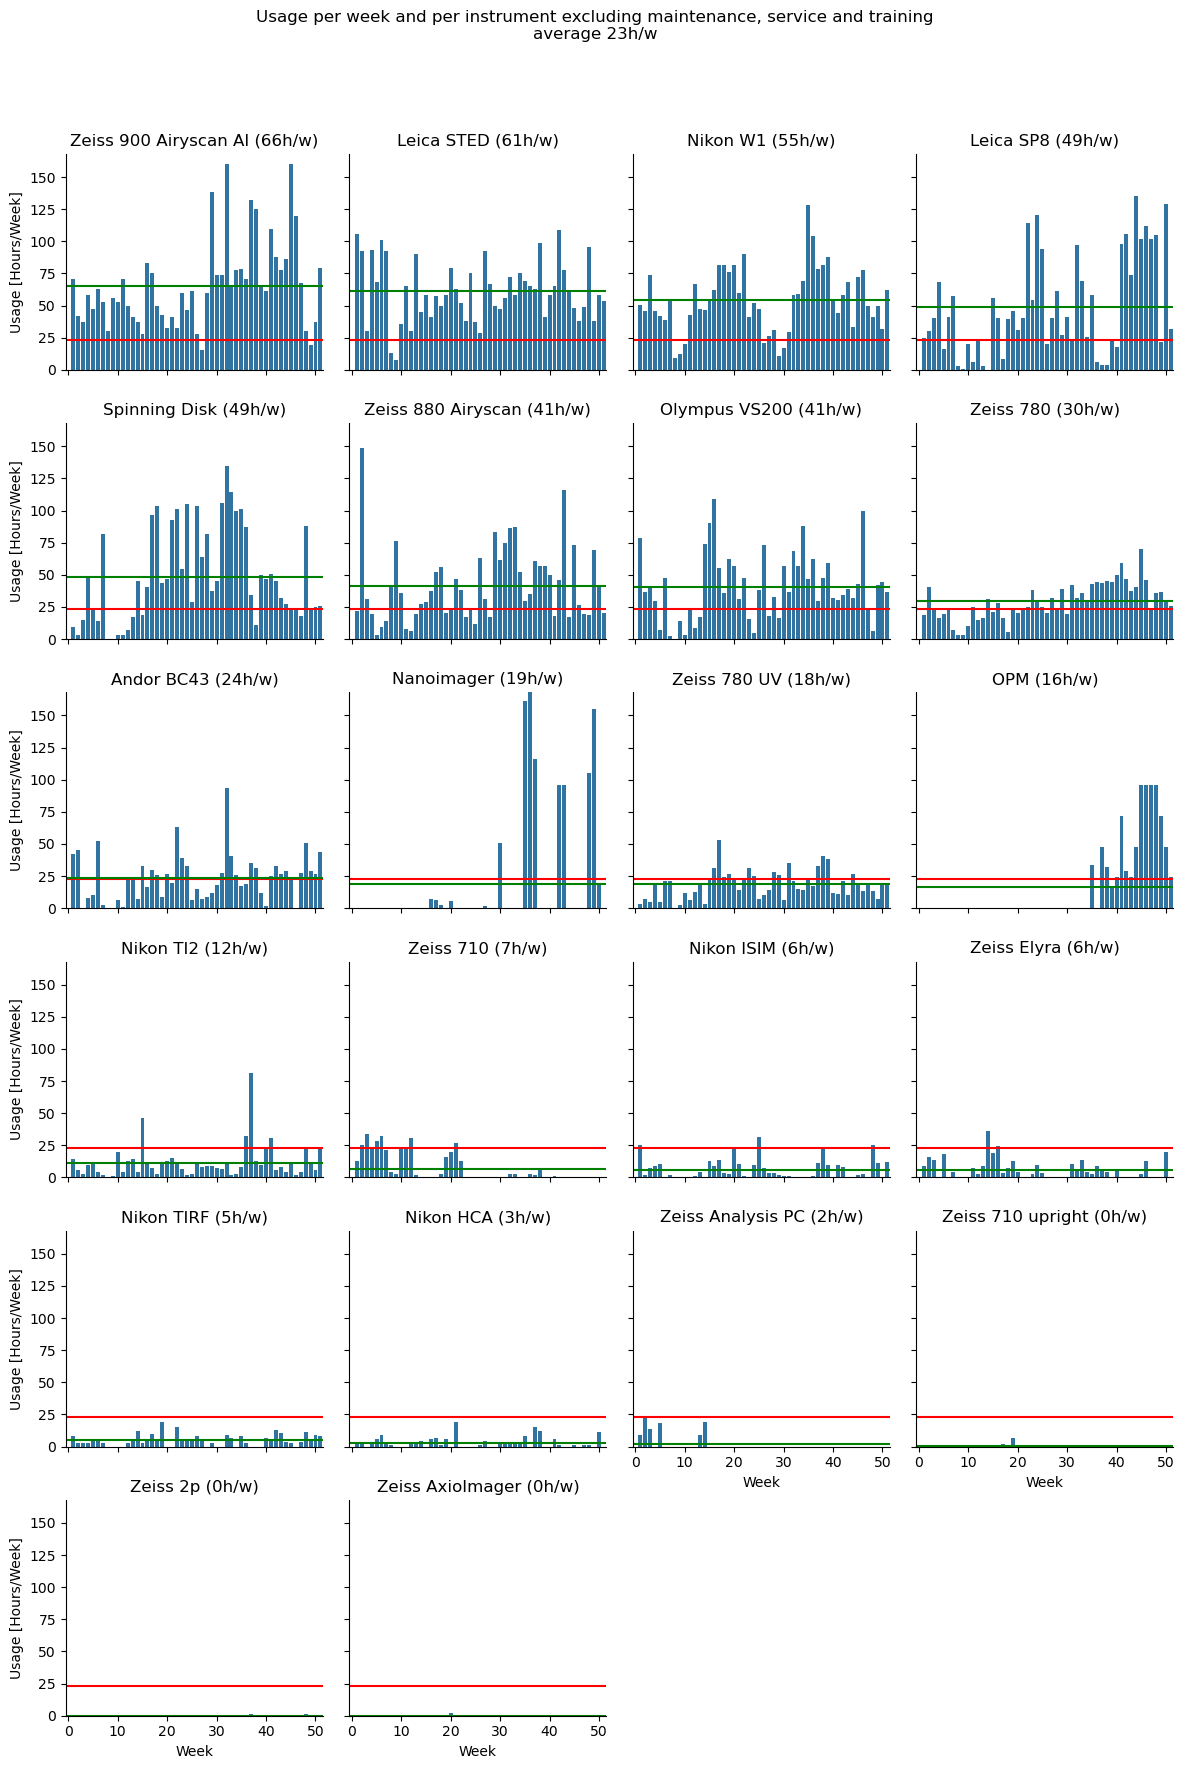

In [21]:
import numpy as np

# figure for each instruments
plt.figure(figsize=(30, 20))
# col_order = [*usage["Instrument"].unique()]
# col_order.sort()
col_order = bookings.groupby('instrument')['hours'].sum().sort_values(ascending=False).index
g = sns.FacetGrid(usage, col="Instrument", col_wrap=4, col_order=col_order)
p = g.map(sns.barplot, "Week", "Usage", order=np.arange(num_weeks))
averages = usage.groupby("Instrument")["Usage"].agg(["mean"])
avg_global = averages.mean()[0]

for k, a in enumerate(p.axes):
    mic = a.get_title().replace("Instrument = ", "")
    avg = averages["mean"][mic]
    a.set_title(f"{mic} ({avg:.0f}h/w)")
    # a.text(15,130,f'average:{avg:.0f}h/w')
    # a.set_subtitle(f'average:{avg:.0f}h/w')
    a.axhline(avg_global, color="r", linestyle="-")
    a.axhline(avg, color="g", linestyle="-")
    a.set_ylabel("Usage [Hours/Week]")
    a.set_xticks(np.arange(0, num_weeks, step=10))
    a.set_xticklabels(np.arange(0, num_weeks, step=10))
    a.set_ylim([0,24*7])
plt.subplots_adjust(top=0.9)
plt.suptitle(
    f"Usage per week and per instrument excluding maintenance, service and training\naverage {avg_global:.0f}h/w"
)
plt.savefig(folder / "usage-per-instrument-per-week.pdf")

In [ ]:
with pd.ExcelWriter(folder / "usage_stats.xlsx") as writer:
    hours_div.to_excel(writer, sheet_name="Per division")
    hours_grps.to_excel(writer, sheet_name="Per group")
    hours_insts.to_excel(writer, sheet_name="Per instrument")
    top_user_per_instrument.to_excel(writer, sheet_name="Top user per instrument")
